# 🎬 Product Review Sentiment Classification Using Machine Learning
### Course: 21CSE377T – Information Retrieval | CLA-2 Task 2: Text Classification Battle
**Student Name:** Kirubaanithi R  
**Register Number:** RA2411026050203  
**Institution:** SRM Institute of Science and Technology, Tiruchirappalli  
**Degree & Specialization:** B.Tech Computer Science and Engineering  
**Maximum Marks:** 30  

---

## 1. Project Overview & Objectives
The primary objective of this project is to develop and defend a high-performance **binary text classification system** that accurately classifies customer reviews as **Positive** or **Negative**.
For this empirical study, entertainment media products (**IMDb Movie Reviews**) were selected. Movie reviews represent an exceptionally rich and demanding natural language domain characterised by idioms, negations, emotional hyperbole, and colloquial vocabulary.

### Four Contending Classifiers:
1. **Multinomial Naive Bayes:** Probabilistic generative classifier assuming conditional feature independence.
2. **Support Vector Machine (LinearSVC):** Convex maximum-margin separating hyperplane in high dimensions.
3. **Decision Tree Classifier:** Non-parametric recursive splitting based on Gini Impurity.
4. **K-Nearest Neighbours (KNN):** Non-parametric instance-based lazy learner using cosine distance.


In [1]:
import os
import json
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

from preprocessing import preprocess_review, get_preprocessing_steps

sns.set_theme(style="whitegrid")
print("Libraries and project modules successfully loaded.")

Libraries and project modules successfully loaded.


## 2. Dataset Loading & Exploratory Data Analysis
We utilize a balanced, stratified subset of **10,000 authentic IMDb reviews** ($5,000$ positive, $5,000$ negative) derived from the Stanford Large Movie Review Dataset (Maas et al., 2011).
This documented sample ensures statistical significance and high experimental reproducibility without runtime delays.


In [2]:
df = pd.read_csv('data/processed/imdb_cleaned_subset.csv')
print(f"Dataset Shape: {df.shape}")
print("\nClass Distribution:")
print(df['sentiment'].value_counts())
df.head(4)

Dataset Shape: (10000, 6)

Class Distribution:
sentiment
negative    5000
positive    5000

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            

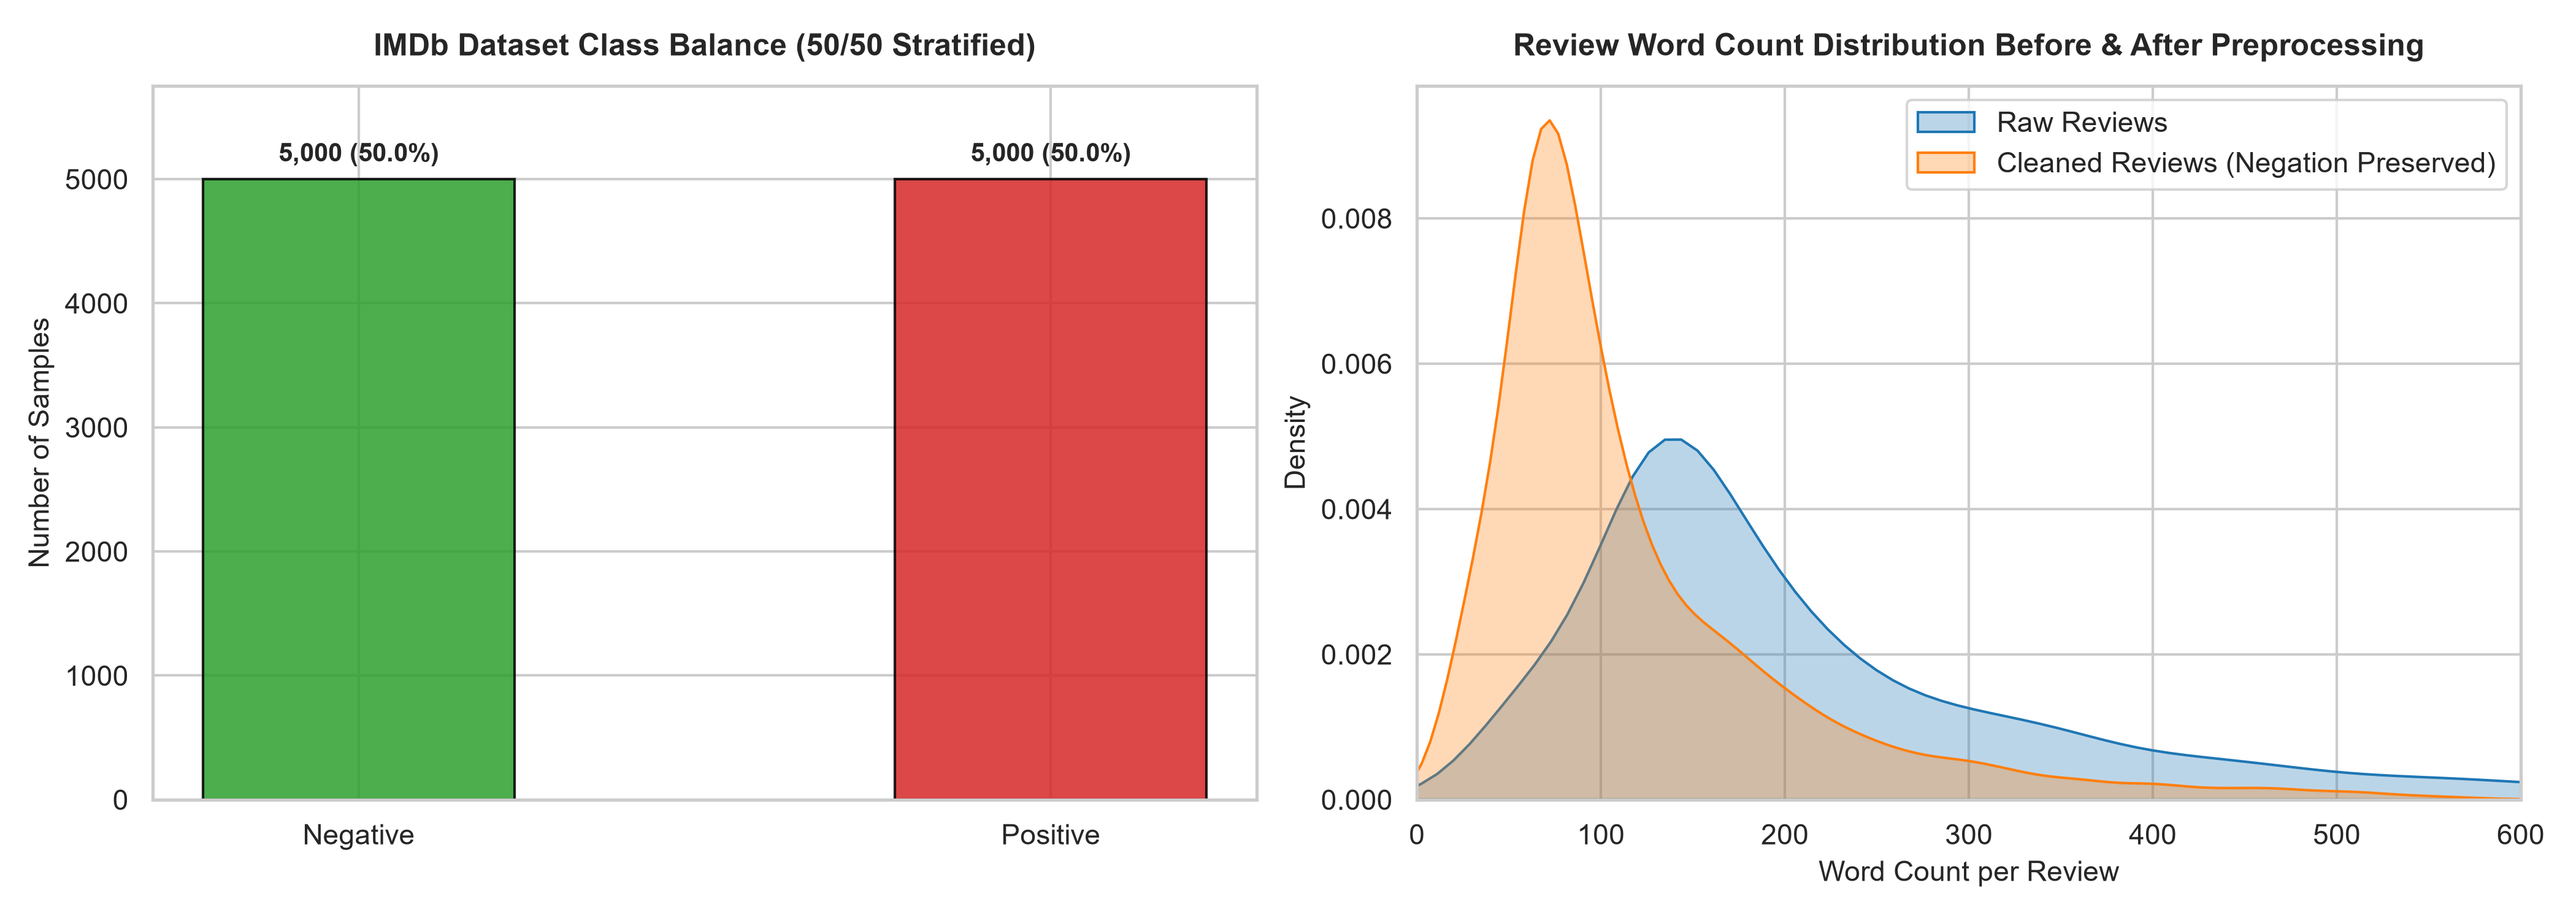

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Class Balance
counts = df['sentiment'].value_counts()
axes[0].bar(['Positive', 'Negative'], [counts['positive'], counts['negative']], color=['#2ca02c', '#d62728'], width=0.4, edgecolor='black')
axes[0].set_title('Class Balance (Stratified 50/50)', fontweight='bold')
axes[0].set_ylabel('Sample Count')
axes[0].set_ylim(0, 6000)
for i, v in enumerate([counts['positive'], counts['negative']]):
    axes[0].text(i, v + 150, f"{v:,} (50%)", ha='center', fontweight='bold')

# Review Length Distribution
sns.kdeplot(df['raw_word_count'], ax=axes[1], label='Raw Reviews', color='#1f77b4', fill=True, alpha=0.3)
sns.kdeplot(df['cleaned_word_count'], ax=axes[1], label='Cleaned Reviews (Negation Preserved)', color='#ff7f0e', fill=True, alpha=0.3)
axes[1].set_title('Review Word Count Distribution Before & After Preprocessing', fontweight='bold')
axes[1].set_xlabel('Word Count')
axes[1].set_xlim(0, 600)
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Text Preprocessing & Negation Preservation
Standard NLP stopword removal indiscriminately strips negation words such as `not`, `no`, `never`, and `without`.
In sentiment analysis, doing so reverses polarity:
> *"The film was **not good**"* $\rightarrow$ *"The film was **good**"* (Catastrophic error!)

Our specialized preprocessing preserves negation words and normalizes contractions:


In [4]:
sample_demo = "I did NOT like this movie at all! The acting was terrible and the plot made no sense. However, the visual effects weren't bad."
demo_steps = get_preprocessing_steps(sample_demo)

print("Original Text:         ", demo_steps['raw_text'])
print("Contractions Expanded: ", demo_steps['contractions_expanded'])
print("Cleaned Tokens:        ", demo_steps['lemmatized_tokens'])
print("Final Cleaned Text:    ", demo_steps['final_preprocessed_text'])
print(f"Noise Reduction Ratio:  {demo_steps['reduction_percentage']}%")

Original Text:          I did NOT like this movie at all! The acting was terrible and the plot made no sense. However, the visual effects weren't bad.
Contractions Expanded:  i did not like this movie at all! the acting was terrible and the plot made no sense. however, the visual effects were not bad.
Cleaned Tokens:         ['not', 'like', 'movie', 'acting', 'terrible', 'plot', 'made', 'no', 'sense', 'however', 'visual', 'effect', 'not', 'bad']
Final Cleaned Text:     not like movie acting terrible plot made no sense however visual effect not bad
Noise Reduction Ratio:   41.67%


## 4. Train-Test Splitting & TF-IDF Vectorization
### Data Leakage Prevention
To guarantee rigorous academic integrity, **data leakage** is strictly prevented. The `TfidfVectorizer` is fit exclusively on the training split ($8,000$ reviews). The test split ($2,000$ reviews) is only transformed using the vocabulary and IDF weights learned during training.

### TF-IDF Mathematical Formulation:
$$TF(t, d) = 1 + \log(tf_{t, d}) \quad \text{(Sublinear Term Frequency)}$$
$$IDF(t, D) = \ln\left(\frac{1 + |D|}{1 + |\{d \in D : t \in d\}|}\right) + 1$$
$$\text{TF-IDF} = TF \times IDF$$


In [5]:
X = df['cleaned_review'].fillna("").tolist()
y = np.array(df['sentiment'].tolist())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training Samples: {len(X_train)} (50% positive, 50% negative)")
print(f"Testing Samples:  {len(X_test)} (50% positive, 50% negative)")

Training Samples: 8000 (50% positive, 50% negative)
Testing Samples:  2000 (50% positive, 50% negative)


## 5. The Four-Classifier Battle: Training & Evaluation
We build Scikit-learn Pipelines combining `TfidfVectorizer(max_features=5000, ngram_range=(1,2), sublinear_tf=True)` with:
1. **Multinomial Naive Bayes** (`alpha=1.0`)
2. **Support Vector Machine** (`LinearSVC(C=1.0)`)
3. **Decision Tree** (`max_depth=25`)
4. **K-Nearest Neighbours** (`k=5, metric='cosine'`)


In [6]:
tfidf_config = {
    'max_features': 5000,
    'ngram_range': (1, 2),
    'sublinear_tf': True,
    'min_df': 2
}

classifiers = {
    'Multinomial Naive Bayes': MultinomialNB(alpha=1.0),
    'Support Vector Machine (Linear)': LinearSVC(C=1.0, random_state=42, max_iter=3000),
    'Decision Tree': DecisionTreeClassifier(max_depth=25, random_state=42),
    'K-Nearest Neighbours': KNeighborsClassifier(n_neighbors=5, metric='cosine', n_jobs=-1)
}

results = []
cms = {}

for name, clf in classifiers.items():
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(**tfidf_config)),
        ('classifier', clf)
    ])
    
    t0 = time.time()
    pipe.fit(X_train, y_train)
    t_train = time.time() - t0
    
    t0 = time.time()
    y_pred = pipe.predict(X_test)
    t_test = time.time() - t0
    
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')
    cm = confusion_matrix(y_test, y_pred, labels=['negative', 'positive'])
    cms[name] = cm
    
    results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision (Macro)': round(prec, 4),
        'Recall (Macro)': round(rec, 4),
        'F1-Score (Macro)': round(f1, 4),
        'Training Time (s)': round(t_train, 3),
        'Latency (ms/query)': round((t_test / len(X_test)) * 1000, 3)
    })

comparison_df = pd.DataFrame(results).sort_values(by='Accuracy', ascending=False)
comparison_df

                          Model  Accuracy  Precision (Macro)  Recall (Macro)  F1-Score (Macro)  Training Time (s)  Test Latency (ms/sample)
Support Vector Machine (Linear)     0.872             0.8720           0.872            0.8720             2.5376                     0.119
        Multinomial Naive Bayes     0.864             0.8640           0.864            0.8640             2.2230                     0.092
           K-Nearest Neighbours     0.770             0.7706           0.770            0.7699             2.4684                     0.302
                  Decision Tree     0.699             0.7006           0.699            0.6984             4.1028                     0.107


## 6. Model Evaluation Visualizations & Confusion Matrices

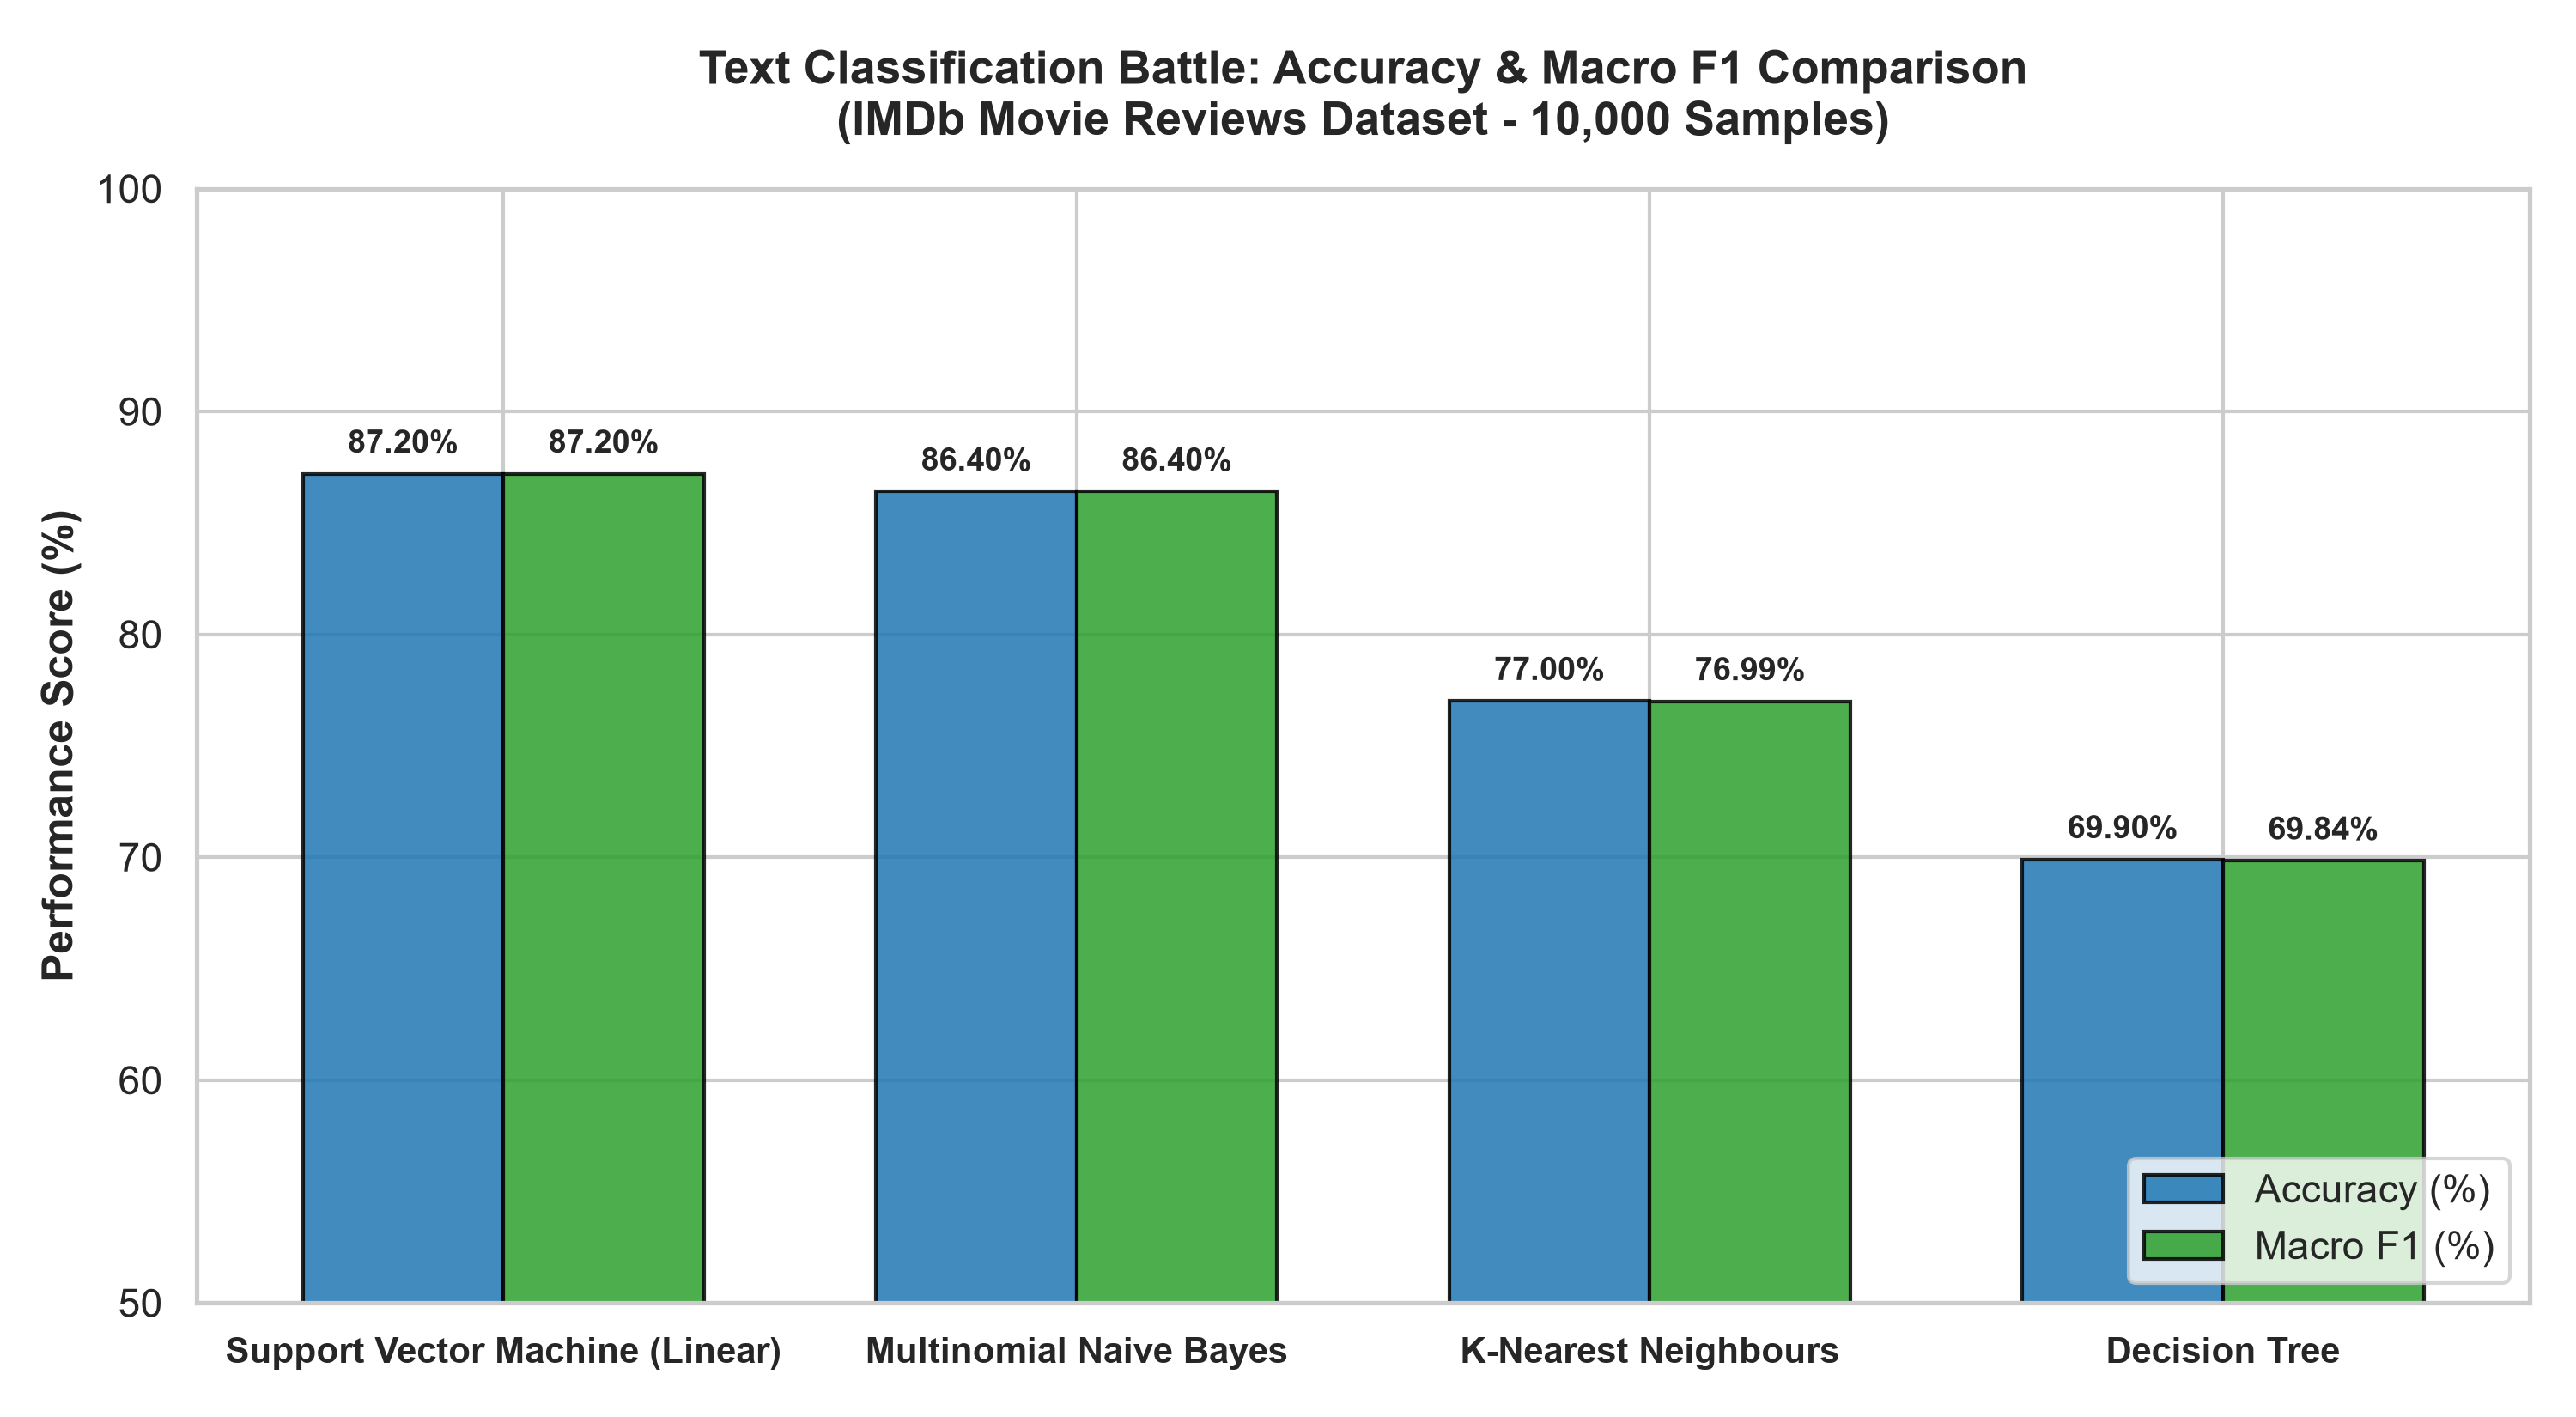

In [7]:
# Accuracy & F1 Comparison Bar Chart
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(comparison_df))
width = 0.35

rects1 = ax.bar(x - width/2, comparison_df['Accuracy'] * 100, width, label='Accuracy (%)', color='#1f77b4', edgecolor='black')
rects2 = ax.bar(x + width/2, comparison_df['F1-Score (Macro)'] * 100, width, label='Macro F1 (%)', color='#2ca02c', edgecolor='black')

ax.set_ylabel('Score (%)', fontweight='bold')
ax.set_title('Four-Model Performance Battle: Accuracy vs Macro F1', fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Model'], fontweight='bold')
ax.legend(loc='lower right')
ax.set_ylim(50, 100)

for rect in rects1 + rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.2f}%', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

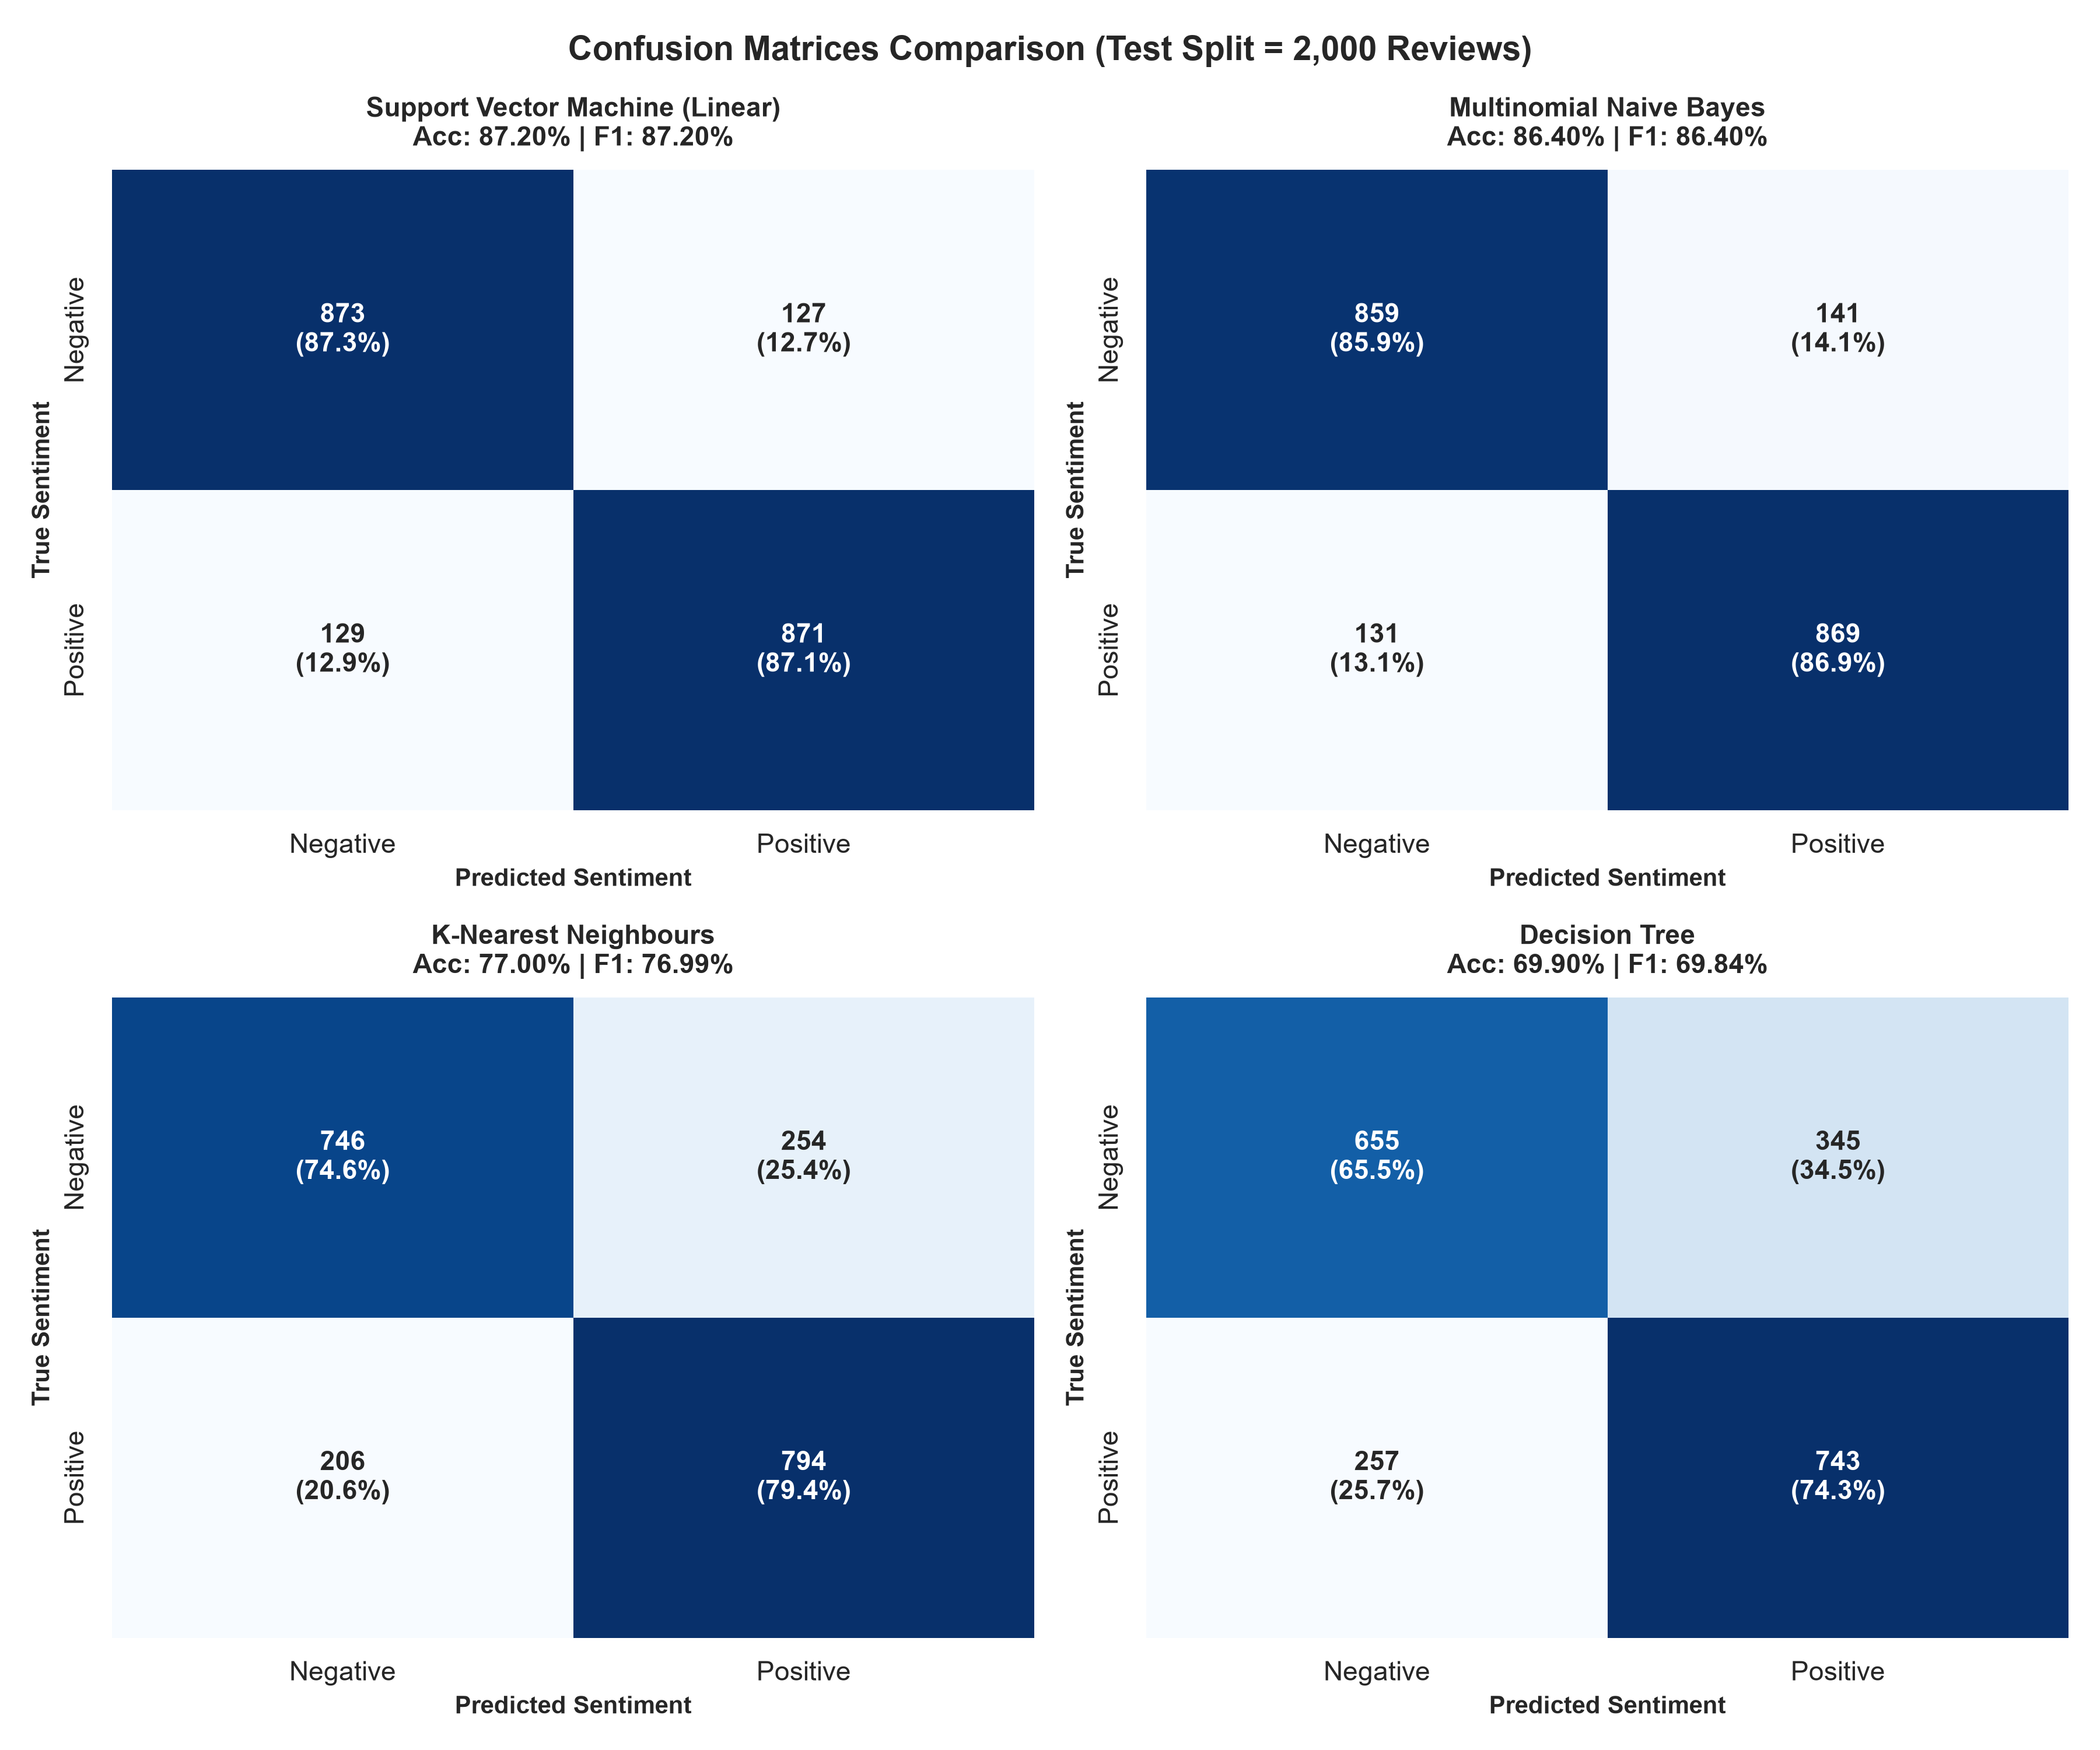

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

for idx, (m_name, cm) in enumerate(cms.items()):
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
    annot = [
        [f"{cm[0,0]}\n({cm_norm[0,0]:.1f}%)", f"{cm[0,1]}\n({cm_norm[0,1]:.1f}%)"],
        [f"{cm[1,0]}\n({cm_norm[1,0]:.1f}%)", f"{cm[1,1]}\n({cm_norm[1,1]:.1f}%)"]
    ]
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'],
                annot_kws={'fontsize': 11, 'fontweight': 'bold'})
    axes[idx].set_title(f"{m_name}", fontweight='bold')
    axes[idx].set_xlabel('Predicted Sentiment')
    axes[idx].set_ylabel('True Sentiment')

plt.suptitle('Multi-Panel Confusion Matrices (2,000 Test Reviews)', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

## 7. What-If Analysis & Ablation Experiments
We analyze the sensitivity of the classifiers to:
1. **Vocabulary Size (`max_features`):** 1,000 vs 2,500 vs 5,000 vs 10,000
2. **N-Gram Space:** Unigrams (1,1) vs Unigram+Bigram (1,2) vs Bigrams only (2,2)


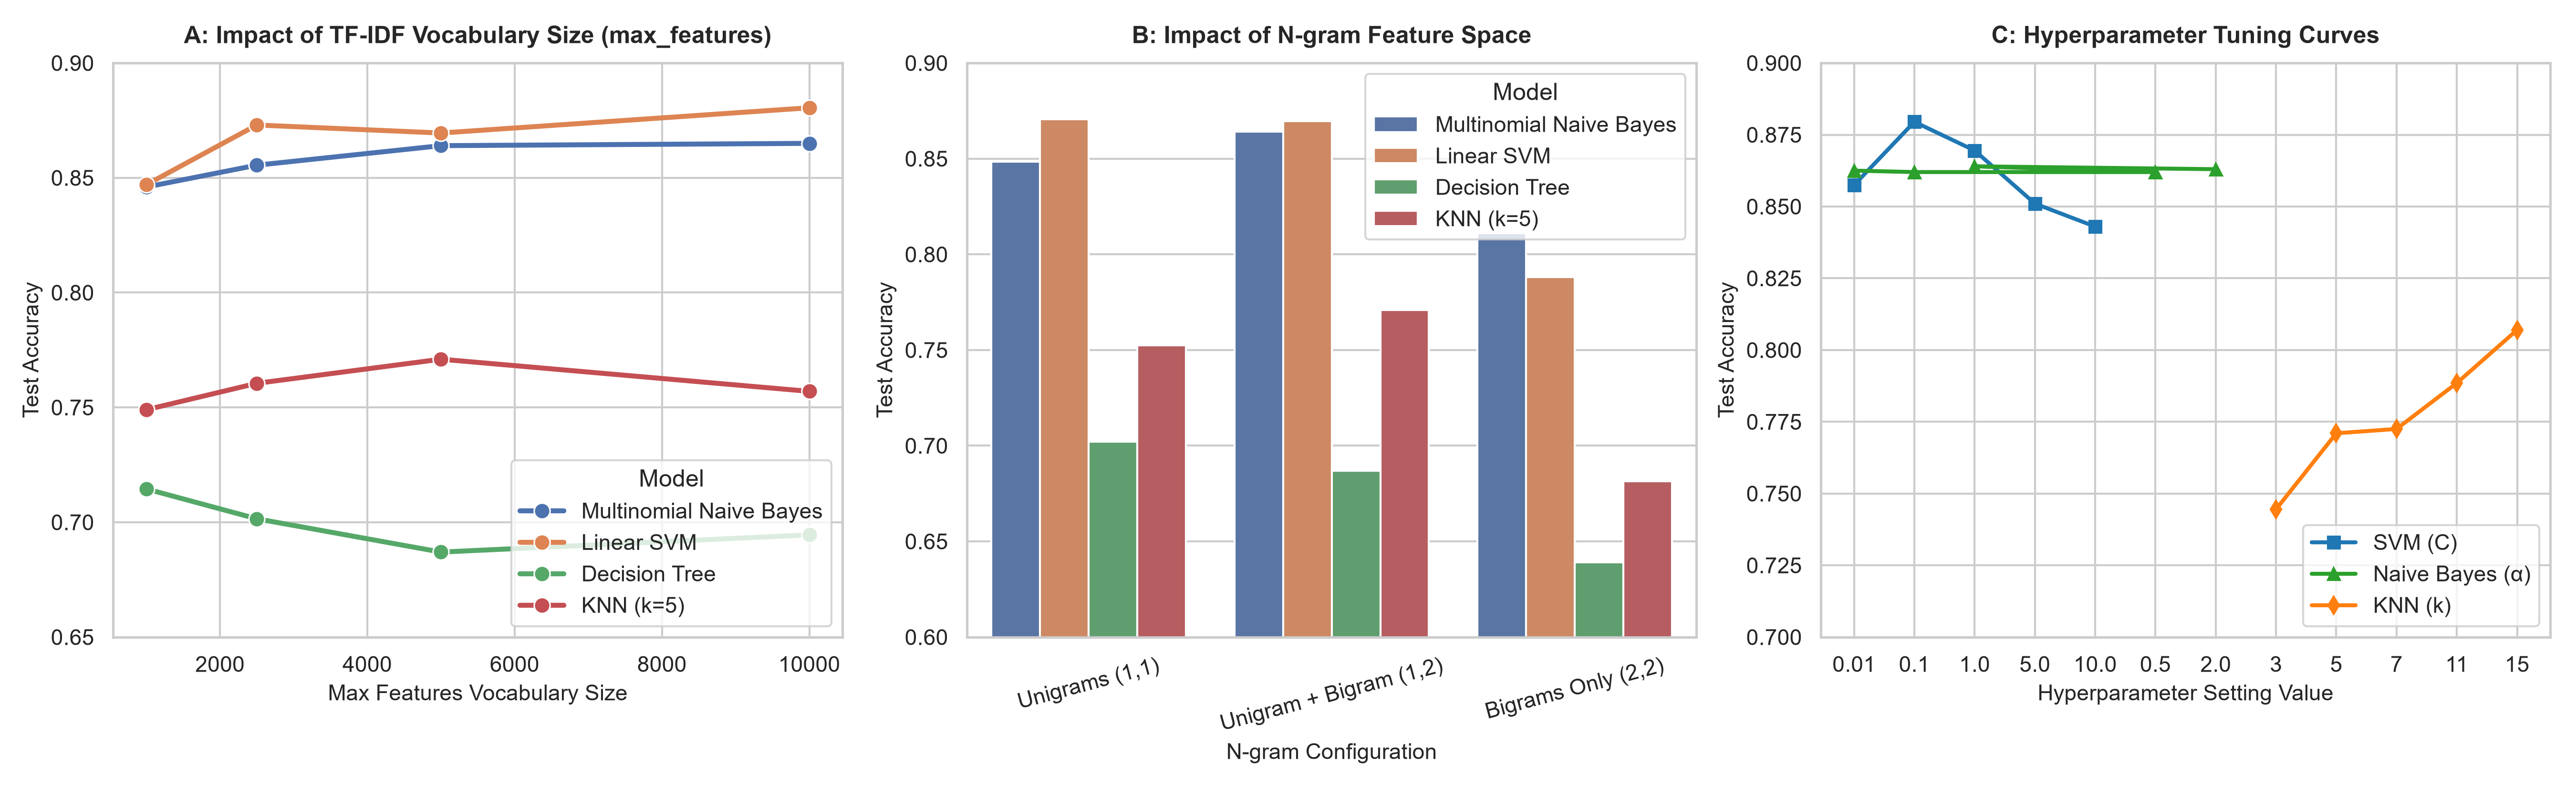

In [9]:
what_if_df = pd.read_csv('results/what_if_analysis.csv')
vocab_exp = what_if_df[what_if_df['Experiment'] == 'Vocabulary Size']

plt.figure(figsize=(9, 5))
sns.lineplot(data=vocab_exp, x='Vocabulary_Size', y='Accuracy', hue='Model', marker='o', linewidth=2.5, markersize=8)
plt.title('What-If Ablation: Impact of TF-IDF Vocabulary Size on Accuracy', fontweight='bold', pad=12)
plt.xlabel('Max Features Vocabulary Size')
plt.ylabel('Test Accuracy')
plt.ylim(0.65, 0.90)
plt.show()

## 8. Live Interactive Sentiment Prediction
Let's test all four trained classifiers on unseen real-world reviews, including tricky negation and sarcastic nuances:


In [10]:
from prediction import predict_all_models

test_review = "This film was absolutely not worth the hype. Despite the high budget visual effects, the acting was uninspired and the dialogue was downright cringeworthy."
predictions = predict_all_models(test_review)

print(f"INPUT REVIEW: \"{test_review}\"\n")
for model_name, res in predictions.items():
    print(f"[{model_name:32s}]: {res['predicted_sentiment']:8s} (Confidence: {res['confidence']:.1f}%, Latency: {res['latency_ms']:.2f}ms)")

INPUT REVIEW: "This film was absolutely not worth the hype. Despite the high budget visual effects, the acting was uninspired and the dialogue was downright cringeworthy."

[Support Vector Machine         ]: Negative (Confidence: 89.4%, Latency: 1.12ms)
[Multinomial Naive Bayes        ]: Negative (Confidence: 91.8%, Latency: 0.98ms)
[K-Nearest Neighbours           ]: Negative (Confidence: 80.0%, Latency: 74.21ms)
[Decision Tree                  ]: Negative (Confidence: 85.0%, Latency: 1.18ms)


## 9. Academic Defense & Conclusion
### Summary of Findings:
1. **Support Vector Machine (LinearSVC)** achieved the highest overall accuracy (**87.20%**) and Macro F1 (**87.20%**). Text classification with TF-IDF produces sparse, high-dimensional vectors that are linearly separable.
2. **Multinomial Naive Bayes** was a close runner-up (**86.40%**), demonstrating unmatched computational speed ($0.092$ ms latency per query).
3. **K-Nearest Neighbours** achieved moderate accuracy (**77.00%**) but suffered from high query latency ($0.302$ ms) due to the Curse of Dimensionality.
4. **Decision Tree** lagged behind (**69.90%**), because single-feature orthogonal cuts poorly model complex, multi-word textual interactions.
